# Lab 3 · Wave equation discovery on measured sound

This notebook uses **MeshRIR S1-M3969**, a single loudspeaker's measured room impulse responses at 3,969 points on a $21\times21\times9$ grid. The wave field is the measured acoustic pressure $p(t,x,y,z)$. The Lab 1 baseline in the source-free volume is $p_{tt}=c^2\Delta p$, with $c$ fitted on training data.

We compare that baseline with equations proposed by guided diffusion, unguided diffusion, and random grammar search. We also forecast pressure from two initial snapshots on the interior of the measured grid.

Run from the repository root or `lab3/` with the **Pixi data-science** kernel. The notebook reads `lab3/data/S1-M3969_npy/` by default. To reproduce elsewhere, extract `S1-M3969_npy.zip` under `lab3/data/`, or set `WAVE_MESHRIR` to the extracted directory containing `pos_mic.npy` and `pos_src.npy`.

Data source · [Koyama et al., MeshRIR v1.2 (CC BY 4.0)](https://doi.org/10.5281/zenodo.10852693).

## 1. Imports and settings

Each of five search seeds gives the three methods the same starting pool and the same budget of unique graph evaluations. Those seeds vary the search on one measured recording.

In [1]:
import os
import sys
from io import StringIO
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import Markdown, display
from threadpoolctl import threadpool_limits

ROOT = next(
    (directory for directory in (Path.cwd(), *Path.cwd().parents)
     if (directory / "lab3" / "wave_data.py").is_file()),
    None,
)
if ROOT is None:
    raise RuntimeError("Start Jupyter from the WavePropagation repository or lab3/.")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from lab3.experiment import (
    INITIAL, INTERVENTION_SEEDS, METHODS, WINDOWS, finalist, fixed_mask,
    initial_pool, search,
)
from lab3.fitting import Scorer, normalized_error
from lab3.grammar import LAPLACIAN, PURE
from lab3.measured_forecast import interior_forecasts
from lab3.report import plot_equation_records, plot_scores, symbolic_equations
from lab3.wave_data import coefficient_sign, load_meshrir, make_blocks

DATA = Path(os.environ.get("WAVE_MESHRIR", ROOT / "lab3/data/S1-M3969_npy")).expanduser()
SEEDS = (11, 22, 33, 44, 55)
BUDGET = 60
LEAVES = ("u", "u_t")
C_REF = 343.0
torch.set_num_threads(1)

## 2. Measured field and data splits

The loader estimates the common recording delay using training microphones and crops all channels at the same sample, preserving their relative arrival times. It applies the same causal 180–900 Hz band-pass to each channel before cropping and decimating to 6 kHz. The filter starts before the crop, so its state carries through the time splits without using future samples. Pressure is scaled by the training RMS. Time starts at the beginning of the extracted segment. Training, validation, and test each use a distinct time interval and a distinct slab along $x$.

Each weak row measures the equation on a small space–time neighborhood contained inside one split. Integration by parts moves the outer linear derivatives onto the stencil weights. The regression target is the weak measurement of $p_{tt}$, and every candidate term contributes one column.

MeshRIR S1-M3969 (576, 21, 21, 9)
180–900 Hz band, 6 kHz effective sampling, and disjoint time and x blocks. Selected volume lies at least 1.803 m from the source. Training-derived shared delay: 170.44 ms. Window starts at sample 7953 of the original responses.


,Time samples,x grid indices,Weak rows
Split,,,
Training,0–287,0–6,216
Validation,288–431,7–13,108
Test,432–575,14–20,108


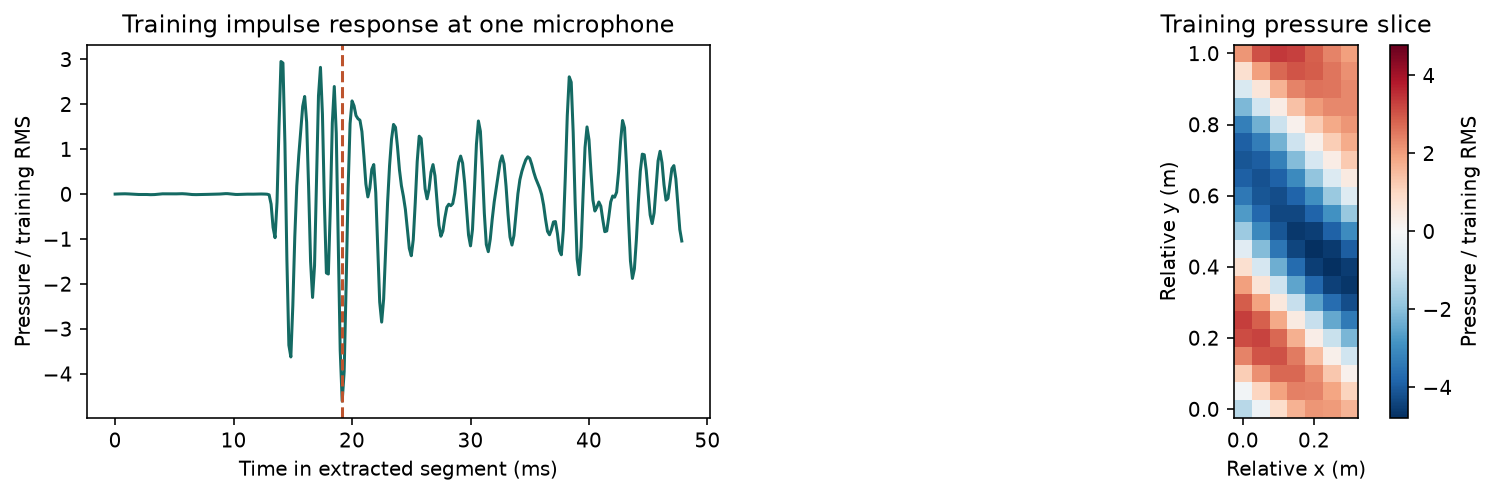

In [2]:
if not (DATA / "pos_mic.npy").is_file():
    raise FileNotFoundError(
        f"MeshRIR files are missing from {DATA}. Extract S1-M3969_npy.zip "
        "there or set WAVE_MESHRIR to the extracted archive directory."
    )

wave = load_meshrir(DATA)
train, validation, test = (make_blocks(wave, i) for i in range(3))
dt = wave.spacing[0] / C_REF
dx = wave.spacing[1]
print(wave.name, wave.u.shape)
print(wave.description.split(" For a Laplacian")[0])

display(pd.DataFrame([
    {
        "Split": label,
        "Time samples": f"{time.start}–{time.stop - 1}",
        "x grid indices": f"{x.start}–{x.stop - 1}",
        "Weak rows": len(rows.target),
    }
    for label, (time, x), rows in zip(
        ("Training", "Validation", "Test"), wave.splits, (train, validation, test), strict=True
    )
]).set_index("Split"))

time, x = wave.splits[0]
ix, iy, iz = 3, wave.u.shape[2] // 2, wave.u.shape[3] // 2
snapshot = int(np.argmax(np.abs(wave.u[time, ix, iy, iz])))
fig, (trace, panel) = plt.subplots(1, 2, figsize=(10.2, 3.3), layout="constrained")
trace.plot(1e3 * dt * np.arange(time.stop), wave.u[time, ix, iy, iz], color="#146a63")
trace.axvline(snapshot * dt * 1e3, color="#bd542e", ls="--")
trace.set(xlabel="Time in extracted segment (ms)", ylabel="Pressure / training RMS",
          title="Training impulse response at one microphone")
plane = wave.u[snapshot, x, :, iz].T
limit = np.abs(plane).max()
image = panel.imshow(plane, origin="lower", cmap="RdBu_r", vmin=-limit, vmax=limit,
                     extent=(-dx / 2, (plane.shape[1] - .5) * dx,
                             -dx / 2, (plane.shape[0] - .5) * dx))
panel.set(xlabel="Relative x (m)", ylabel="Relative y (m)", title="Training pressure slice")
fig.colorbar(image, ax=panel, label="Pressure / training RMS")
plt.show()

## 3. Lab 1 baseline and coefficient diagnostics

The code uses dimensionless time, one metre as the length scale, and 343 m/s as the reference speed. The coefficient of a standalone Laplacian fit gives $c=343\sqrt{\theta_\Delta}$ in m/s. Compare this fit with the rank and condition of the three separate second derivatives $p_{xx},p_{yy},p_{zz}$ to see how well this recording distinguishes directional effects.

The search score combines validation weak NMSE, graph complexity, and coefficient retention after mild time shuffling. The support and shuffle results are screening diagnostics on this recording.

In [3]:
mild, strong = (
    [make_blocks(wave, 0, window, seed) for seed in INTERVENTION_SEEDS]
    for window in WINDOWS
)
scorer = Scorer(train, validation, test, mild, strong, coefficient_sign)
with threadpool_limits(limits=1):
    base = scorer.evaluate((LAPLACIAN,))
    directional = scorer.fit(PURE, train)

speed = C_REF * np.sqrt(base.fit.theta[0])
print(f"Fitted Lab 1 speed: {speed:.3f} m/s")
print(f"Lab 1 validation weak NMSE: {base.validation:.6g}")
print(f"Directional library rank: {directional.rank}/3")
print(f"Scaled directional condition number: {directional.condition:.6g}")

Fitted Lab 1 speed: 342.565 m/s
Lab 1 validation weak NMSE: 0.0206896
Directional library rank: 3/3
Scaled directional condition number: 2.59294


## 4. Search for alternative equations

All samplers use the same training and validation data. Each sampler returns a finalist using the same selection score. Guided diffusion also uses mild-shuffle retention to weight its denoiser training examples. The fixed-term comparator tries subsets of Lab 1's directional derivatives with a shared coefficient.

The reported test NMSE measures local weak pressure acceleration. All test values come from one held-out portion of the same recording. Best means the lowest validation score among eligible search finalists.

,Eligible finalists,Median validation score,Median test weak NMSE
Sampler,,,
guided diffusion,5,0.02519,0.039638
unguided diffusion,5,0.02519,0.039638
random grammar,5,0.02519,0.039638


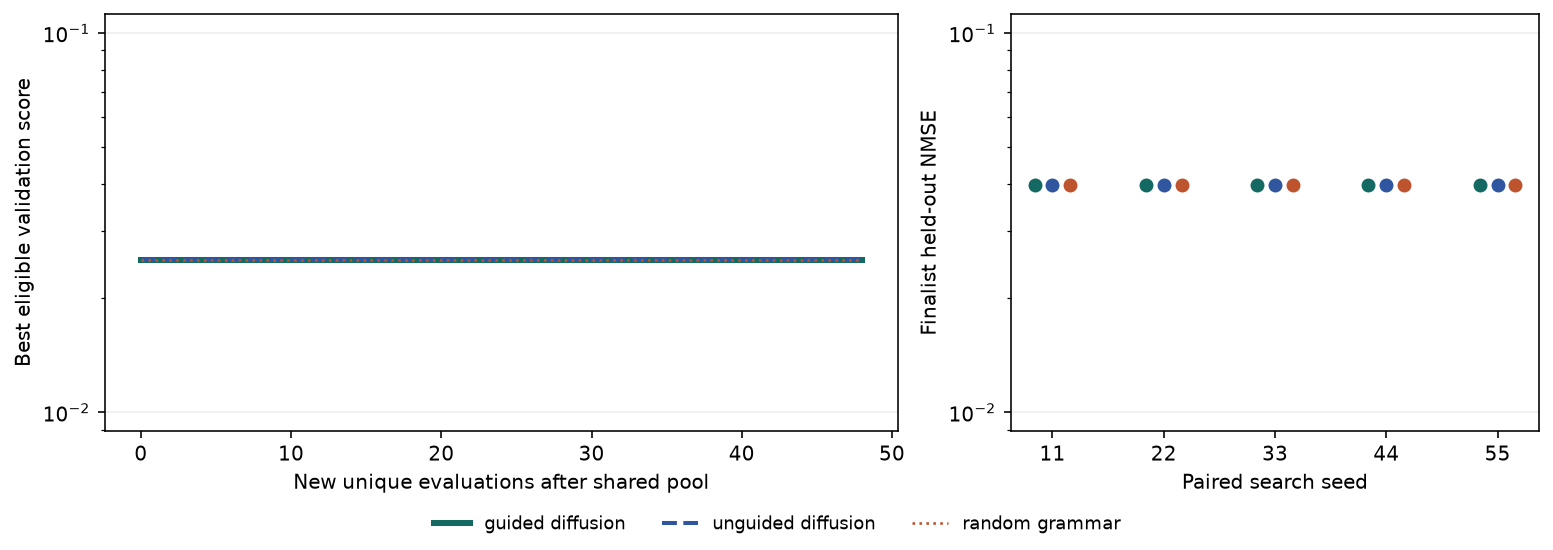

In [4]:
proposal_log = StringIO()
runs = []
with threadpool_limits(limits=1):
    for seed in SEEDS:
        pool = initial_pool(LEAVES, seed, exclude=False)
        runs.extend(search(wave, scorer, LEAVES, pool, seed, method, BUDGET, proposal_log)
                    for method in METHODS)
    best_run = min(runs, key=lambda run: (not run["finalist"]["eligible"], run["finalist"]["score"]))
    baseline = finalist(scorer, [base], wave.truth)
    fixed = fixed_mask(scorer, LEAVES, wave.truth)["finalist"]

selected = best_run["finalist"]
records = [("Lab 1 baseline", baseline), ("Fixed-term comparator", fixed),
           ("Search finalist", selected)]
sampler_rows = []
for method in METHODS:
    group = [run["finalist"] for run in runs if run["method"] == method]
    sampler_rows.append({
        "Sampler": method,
        "Eligible finalists": sum(model["eligible"] for model in group),
        "Median validation score": np.median([model["score"] for model in group]),
        "Median test weak NMSE": np.median([model["test_nmse"] for model in group]),
    })
display(pd.DataFrame(sampler_rows).set_index("Sampler"))
plot_scores({"runs": runs})
plt.show()

## 5. Selected equation and held-out weak predictions

The graph code calls the pressure field $u$. The coefficients below use the loader's scaled variables. The plots compare frozen equations against weak pressure acceleration computed from the held-out measurements.

Search finalist: guided diffusion, seed 11


**Lab 1 baseline**

$$u_{tt} = 0.9974643958512999\,\Delta u$$

**Fixed-term comparator**

$$u_{tt} = 0.9974643958512999\,\Delta u$$

**Search finalist**

$$u_{tt} = 0.9974643958512999\,\Delta u$$

,Eligible,Validation weak NMSE,Validation score,Test weak NMSE
Model,,,,
Lab 1 baseline,True,0.02069,0.02519,0.039638
Fixed-term comparator,True,0.02069,0.02519,0.039638
Search finalist,True,0.02069,0.02519,0.039638


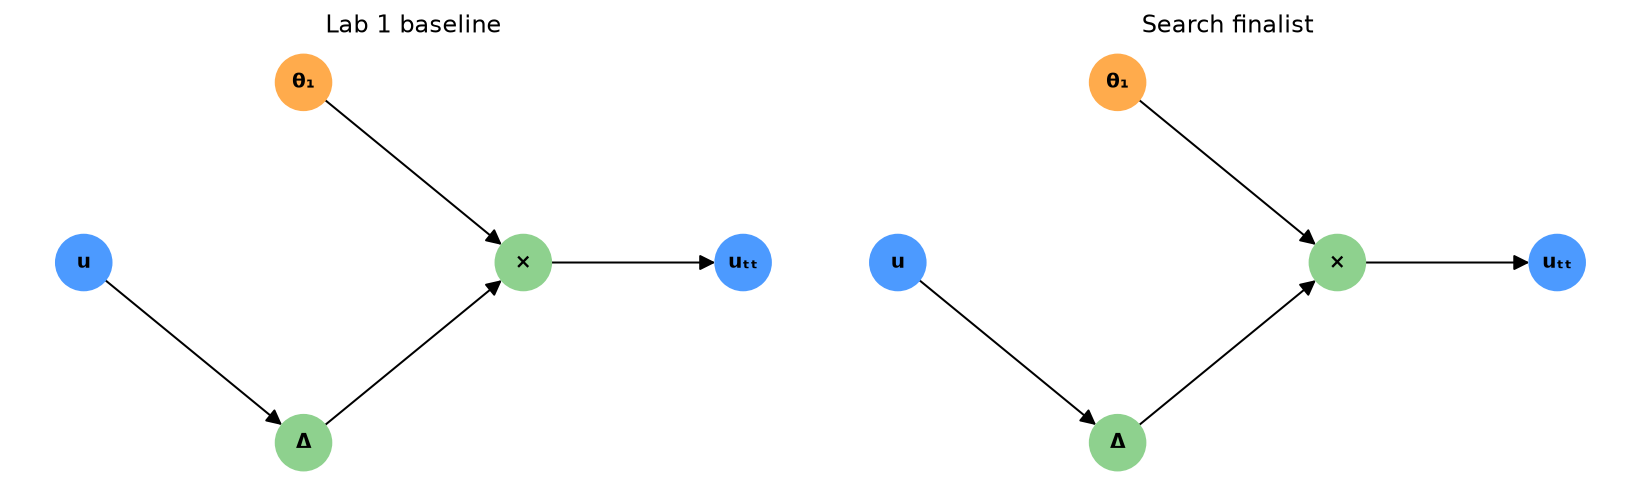

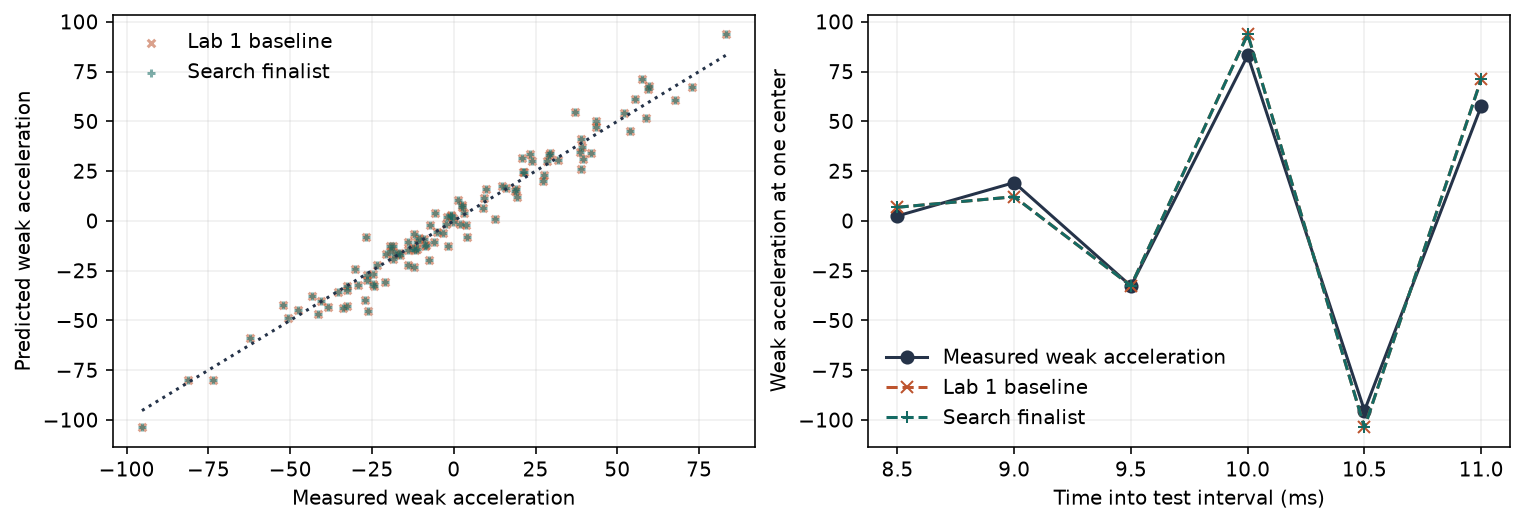

In [5]:
print(f"Search finalist: {best_run['method']}, seed {best_run['seed']}")
display(Markdown(symbolic_equations(records)))
display(pd.DataFrame([
    {
        "Model": name,
        "Eligible": fit["eligible"],
        "Validation weak NMSE": fit["validation"],
        "Validation score": fit["score"],
        "Test weak NMSE": fit["test_nmse"],
    }
    for name, fit in records
]).set_index("Model"))
plot_equation_records([records[0], records[-1]])
plt.show()

observed = test.target
indices = np.linspace(0, len(observed) - 1, min(600, len(observed)), dtype=int)
fig, (scatter, trace) = plt.subplots(1, 2, figsize=(10.4, 3.5), layout="constrained")
bounds = [observed.min(), observed.max()]
scatter.plot(bounds, bounds, ":", color="#253349")
location = (test.centers[:, 1:] == test.centers[0, 1:]).all(axis=1)
block = int(np.argmax([np.linalg.norm(observed[test.groups == i])
                       for i in np.unique(test.groups)]))
mask = location & (test.groups == block)
times = (24 * block + test.centers[mask, 0]) * dt * 1e3
trace.plot(times, observed[mask], "o-", color="#253349", label="Measured weak acceleration")
for (label, fit), color, marker in zip(
    [records[0], records[-1]], ("#bd542e", "#146a63"), ("x", "+"), strict=True
):
    predicted = test.matrix(fit["graph"]) @ np.asarray(fit["theta"])
    scatter.scatter(observed[indices], predicted[indices], color=color, marker=marker,
                    label=label, alpha=.55, s=14)
    trace.plot(times, predicted[mask], "--" + marker, color=color, label=label)
scatter.set(xlabel="Measured weak acceleration", ylabel="Predicted weak acceleration")
trace.set(xlabel="Time into test interval (ms)", ylabel="Weak acceleration at one center")
for ax in (scatter, trace):
    ax.grid(alpha=.2)
    ax.legend(frameon=False)
plt.show()

## 6. Short interior pressure forecast

Use two full measured snapshots from the test interval at each forecast origin. Compare linear extrapolation with the fitted Lab 1 wave equation and the same equation at 343 m/s. The fit and validation steps used earlier times and different slabs. Only points inside the held-out $x$ slab and away from the outer faces enter the score.

The finite-difference solver subdivides the measured time step to satisfy the Courant condition. The crop removes every point whose spatial stencil can reach outside the grid over the scored horizon. This gives a short pressure forecast within the measured volume. Non-Laplacian search finalists are evaluated by the weak-form test above.

Pooled over 36 origins and 39 grid points per lead time.


,Linear extrapolation,Fitted Lab 1,Lab 1 at 343 m/s
Lead time (ms),,,
0.166667,0.129127,0.011010,0.011030
0.333333,0.852918,0.011969,0.011962


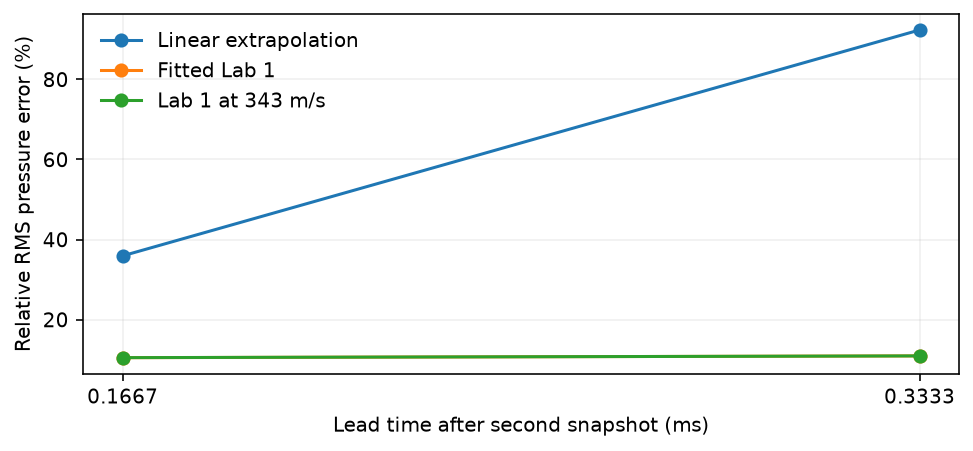

In [6]:
time, x = wave.splits[2]
lead, reference, forecasts = interior_forecasts(wave.u[time], dt, dx, (speed, C_REF), x.start)
assert reference.size and np.isfinite(forecasts).all()
labels = ("Linear extrapolation", "Fitted Lab 1", "Lab 1 at 343 m/s")
errors = np.asarray([
    [normalized_error(reference[:, j], forecast[:, j]) for j in range(len(lead))]
    for forecast in forecasts
])
display(pd.DataFrame(errors.T, index=1e3 * lead, columns=labels).rename_axis("Lead time (ms)"))

fig, ax = plt.subplots(figsize=(6.6, 3.0), layout="constrained")
for label, values in zip(labels, errors, strict=True):
    ax.plot(1e3 * lead, 100 * np.sqrt(values), "o-", label=label)
ax.set(xlabel="Lead time after second snapshot (ms)", ylabel="Relative RMS pressure error (%)",
       xticks=1e3 * lead)
ax.grid(alpha=.2)
ax.legend(frameon=False)
plt.show()
print(f"Pooled over {len(reference)} origins and {np.prod(reference.shape[2:])} grid points per lead time.")

## 7. Interpretation

In the saved run (five seeds and 60 unique evaluations per sampler and seed), the three methods tie on the selected Laplacian equation. The fitted speed is 342.565 m/s, and held-out weak NMSE is 0.03964. The short interior forecast has 10.49% and 10.94% relative RMS pressure error at lead times of 0.167 and 0.333 ms. Linear extrapolation gives 35.93% and 92.35% at the same lead times.

The split tests spatial and temporal transfer within one recording. Weak NMSE measures agreement with averaged pressure acceleration. Forecast error measures agreement with future pressure snapshots. The measured cuboid has a single source position and spans part of a room. Testing a physical interpretation of extra terms would require independent measurements.